# 06 · Leakage under repeated splits

Notebook 04 compared one clip-level split (macro F1 0.886) with one session-aware split (0.856). A single split of each kind cannot tell a real gap from luck.

Here the same linear probe is evaluated on 50 test folds of each kind (5-fold cross-validation repeated 10 times):
- **clip-level**: clips assigned to folds at random, so clips from the same session can sit on both sides (like the original dataset split);
- **session-aware**: whole session groups (from notebook 02) assigned to folds, so a session is never on both sides.

Both keep the classes balanced across folds. The only difference is whether sessions are kept together, so a consistent gap measures leakage.

## 1. Setup and data

In [5]:
import sys
from pathlib import Path

# Make the project root importable (notebooks/ is one level below it)
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data.features import load_features
from src.data.splits import random_group_folds

splits = pd.read_csv(PROJECT_ROOT / "data" / "splits.csv")

# Same input as the linear probe in notebook 04: mean over the 8 time slices
X = load_features(splits).mean(axis=1)   # (1056, 1024)
y = splits["maneuver"].to_numpy()
groups = splits["group"].to_numpy()      # session groups from notebook 02

N_REPEATS, N_FOLDS = 10, 5
print(X.shape, "|", splits["group"].nunique(), "session groups")

(1056, 1024) | 36 session groups


## 2. Why a custom group splitter

In [6]:
def distinct_test_folds(make_folds):
    """Number of different test folds produced over all repeats (ideally N_REPEATS * N_FOLDS)."""
    seen = set()
    for repeat in range(N_REPEATS):
        seen |= {frozenset(test_idx) for _, test_idx in make_folds(repeat)}
    return len(seen)

candidates = {
    "StratifiedKFold (clip-level)": lambda r: StratifiedKFold(N_FOLDS, shuffle=True, random_state=r).split(X, y),
    "StratifiedGroupKFold (sklearn)": lambda r: StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=r).split(X, y, groups),
    "random_group_folds (ours)": lambda r: random_group_folds(y, groups, N_FOLDS, seed=r),
}
for name, make_folds in candidates.items():
    print(f"{name:32s} {distinct_test_folds(make_folds)} distinct test folds out of {N_REPEATS * N_FOLDS}")

StratifiedKFold (clip-level)     50 distinct test folds out of 50
StratifiedGroupKFold (sklearn)   7 distinct test folds out of 50
random_group_folds (ours)        50 distinct test folds out of 50


## 3. Fifty folds of each kind

In [7]:
def linear_probe_scores(train_idx, test_idx):
    """Fit the notebook 04 linear probe on one fold and score it on the held-out clips."""
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))
    probe.fit(X[train_idx], y[train_idx])
    pred = probe.predict(X[test_idx])
    return accuracy_score(y[test_idx], pred), f1_score(y[test_idx], pred, average="macro")

rows = []
for repeat in range(N_REPEATS):
    # Same seed for both kinds in each repeat; only the grouping differs
    cv_by_kind = {
        "clip-level": StratifiedKFold(N_FOLDS, shuffle=True, random_state=repeat).split(X, y),
        "session-aware": random_group_folds(y, groups, N_FOLDS, seed=repeat),
    }
    for kind, folds in cv_by_kind.items():
        for fold, (train_idx, test_idx) in enumerate(folds):
            acc, f1 = linear_probe_scores(train_idx, test_idx)
            # Sessions present on both sides of this fold (0 by construction for session-aware)
            shared = len(set(groups[train_idx]) & set(groups[test_idx]))
            rows.append({"kind": kind, "repeat": repeat, "fold": fold, "test_clips": len(test_idx),
                         "shared_sessions": shared, "accuracy": acc, "macro_f1": f1})
    print(f"repeat {repeat} done")

folds = pd.DataFrame(rows)
folds.groupby("kind")[["test_clips", "shared_sessions", "accuracy", "macro_f1"]].agg(["mean", "std"]).round(3)

repeat 0 done
repeat 1 done
repeat 2 done
repeat 3 done
repeat 4 done
repeat 5 done
repeat 6 done
repeat 7 done
repeat 8 done
repeat 9 done


test_clips         shared_sessions        accuracy         \
                    mean     std            mean    std     mean    std   
kind                                                                      
clip-level         211.2   0.404            34.0  0.833    0.908  0.018   
session-aware      211.2  20.891             0.0  0.000    0.878  0.032   

              macro_f1         
                  mean    std  
kind                           
clip-level       0.911  0.018  
session-aware    0.880  0.033

## 4. Distribution and statistical check

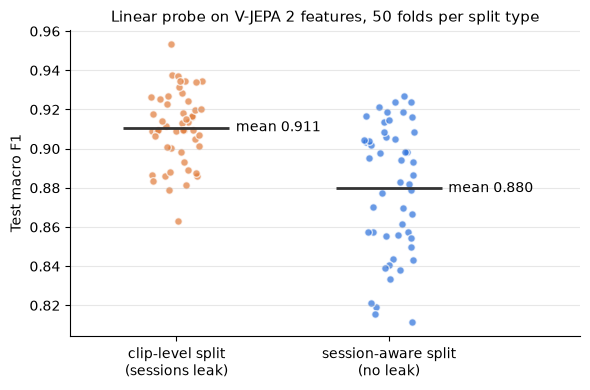

kind    clip-level  session-aware    gap
repeat                                  
0            0.905          0.870  0.035
1            0.912          0.883  0.029
2            0.904          0.879  0.026
3            0.912          0.886  0.025
4            0.912          0.872  0.039
5            0.913          0.888  0.026
6            0.911          0.887  0.023
7            0.910          0.873  0.037
8            0.923          0.878  0.045
9            0.906          0.881  0.025

mean gap 0.031 | repeats with a positive gap: 10 of 10
Mann-Whitney U = 1950, one-sided p = 7.10e-07


In [8]:
# Per-fold macro F1 of each kind, as jittered points with the mean marked
colors = {"clip-level": "#E07B39", "session-aware": "#2A6FDB"}
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(6, 4))
for x, (kind, color) in enumerate(colors.items()):
    scores = folds.loc[folds["kind"] == kind, "macro_f1"]
    ax.scatter(x + rng.uniform(-0.12, 0.12, len(scores)), scores, s=30, color=color, alpha=0.7,
               edgecolor="white", linewidth=1)
    ax.hlines(scores.mean(), x - 0.25, x + 0.25, color="#333333", linewidth=2)
    ax.text(x + 0.28, scores.mean(), f"mean {scores.mean():.3f}", va="center", fontsize=10)

ax.set_xticks([0, 1], ["clip-level split\n(sessions leak)", "session-aware split\n(no leak)"])
ax.set_xlim(-0.5, 1.9)
ax.set_ylabel("Test macro F1")
ax.set_title(f"Linear probe on V-JEPA 2 features, {N_REPEATS * N_FOLDS} folds per split type", fontsize=11)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# Saved for the write-up and a future post (no dataset frames in it)
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "leakage_repeated_splits.png", dpi=200)
plt.show()

# Paired view: in each repeat both kinds share the seed, so compare their means repeat by repeat
by_repeat = folds.pivot_table(index="repeat", columns="kind", values="macro_f1", aggfunc="mean")
by_repeat["gap"] = by_repeat["clip-level"] - by_repeat["session-aware"]
print(by_repeat.round(3))
print(f"\nmean gap {by_repeat['gap'].mean():.3f} | repeats with a positive gap: {(by_repeat['gap'] > 0).sum()} of {N_REPEATS}")

# One-sided test: are clip-level fold scores higher than session-aware ones?
clip = folds.loc[folds["kind"] == "clip-level", "macro_f1"]
session = folds.loc[folds["kind"] == "session-aware", "macro_f1"]
stat, p = mannwhitneyu(clip, session, alternative="greater")
print(f"Mann-Whitney U = {stat:.0f}, one-sided p = {p:.2e}")

- **Leakage is measured, not just suspected.** Over 50 folds of each kind, the same linear probe scores macro F1 0.911 ± 0.018 on clip-level folds and 0.880 ± 0.033 on session-aware folds. The gap is positive in all 10 repeats (0.023 to 0.045, mean 0.031) and a one-sided Mann-Whitney test gives p = 7.1e-07. Folds of the same repeat share training data, so the p-value is somewhat optimistic; the 10-of-10 paired gaps are the more conservative evidence.
- **The mechanism is visible in the folds.** In clip-level folds, 34 of the 36 sessions have clips on both the train and the test side; session-aware folds have none by construction.
- **Clip-level evaluation also understates the uncertainty.** Session-aware scores spread almost twice as much (std 0.033 vs 0.018, lowest fold about 0.81): how well the probe does depends on which sessions are unseen. A random split hides this.
- **The single-split gap of notebook 04 (0.886 vs 0.856) was representative.** Both levels are a few points higher here because each fold trains on 80% of the clips instead of about 70%.
- **Method note.** sklearn's StratifiedGroupKFold produced only 7 distinct test folds out of 50 over 10 seeds, because it sorts groups before shuffling. Session-aware folds therefore use `random_group_folds` (src/data/splits.py), which visits groups in a random order and places each where it best balances the classes.
- **Consequence for the rest of the project.** All results are reported on session-aware splits, and comparisons between models should use repeated group folds rather than a single split.